# Домашняя работа №3

**Дедлайн:** 7 ноября 23:59

**Критерии оценивания:**
- Рядом с каждым заданием в скобках указано, какое количество баллов вы можете за него получить.
- Если в задании содержится некоторый вопрос или требование описать полученный результат, то это не формальность – полный балл за задание можно получить только при наличии внятного ответа или описания.
- Сохраняйте **все** файлы, которые мы просим вас создать и сохранить. Они должны лежать вместе с тетрадкой в вашем репозитории.
- **Штраф** за неправильную сдачу: [в первой домашке (git)](https://github.com/hse-ling-python/hse-ling_26-27/blob/main/homeworks/python2nd_2026_hw1.md) вы тренировались выкладывать домашнее задание правильно: создавать папку в отдельной ветке и делать Pull Request в main. За неправильную сдачу будет **штраф 0,5 балла**.
- За несанкционированное, незадекларированное и необоснованное использование ИИ мы имеем право вас вызывать на защиту вашей работы. В случае неуспешной защиты мы обнулим вашу работу.

**Правила оформления работы:**
- Требования к оформлению домашних заданий прописаны в [первой тетрадке](https://github.com/hse-ling-python/hse-ling_26-27/blob/main/seminars/2026_1_markdown+json.ipynb) учебных материалов.
- Если вам нужно оставить комментарий или ответить на вопрос в задании, делайте это в отдельной текстовой ячейке (можно использовать другие методы выделения при необходимости – например, можно сделать ваш текст другого цвета).
- **Не удаляйте условия заданий и не очищайте ячейки с выводом для удобства проверки!**
- Ваше решение должно работать правильно при последовательном запуске всех ячеек в тетради.

## Установка и импорт модулей

In [4]:
import pandas as pd

In [5]:
import re

Для удобства проверки установку и импорт всех необходимых библиотек производите в этом разделе.

## Подготовка данных (3.25 балла)

В данном домашнем задании вы будете работать с датасетом, содержащим информацию о 250 лучших фильмах по рейтингу Кинопоиска.

Источник данных: [датасет на Kaggle](https://www.kaggle.com/datasets/alexandertesemnikov/kinopoisktop250russiandataset).

Этот же датасет можно скачать по [ссылке из нашего репозитория](https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/kinopoisk-top250.csv).

**Задание 1 (0.5 балла).** Прочитайте датасет из файла. Удалите все столбцы, которые идут после столбца `overview`.

In [6]:
!wget https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/kinopoisk-top250.csv

--2026-11-07 15:25:43--  https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/kinopoisk-top250.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 297908 (291K) [text/plain]
Saving to: ‘kinopoisk-top250.csv’

kinopoisk-top250.cs 100%[===================>] 290.93K  --.-KB/s    in 0.1s    

2026-11-07 15:25:43 (2.49 MB/s) - ‘kinopoisk-top250.csv’ saved [297908/297908]



In [7]:
df = pd.read_csv("kinopoisk-top250.csv")
df

,rating,movie,year,country,rating_ball,overview,director,screenwriter,actors,url_logo
0,0,Побег из Шоушенка,1994,США,9.111,Бухгалтер Энди Дюфрейн обвинён в убийстве собс...,Фрэнк Дарабонт,Фрэнк Дарабонт; Стивен Кинг,Тим Роббинс; Морган Фриман; Боб Гантон; Уильям...,'https://st.kp.yandex.net/images/film_iphone/i...
1,1,Зеленая миля,1999,США,9.062,Пол Эджкомб — начальник блока смертников в тюр...,Фрэнк Дарабонт,Фрэнк Дарабонт; Стивен Кинг,Том Хэнкс; Дэвид Морс; Бонни Хант; Майкл Кларк...,'https://st.kp.yandex.net/images/film_iphone/i...
2,2,Форрест Гамп,1994,США,8.913,От лица главного героя Форреста Гампа; слабоум...,Роберт Земекис,Эрик Рот; Уинстон Грум,Том Хэнкс; Робин Райт; Салли Филд; Гэри Синиз;...,'https://st.kp.yandex.net/images/film_iphone/i...
3,3,Список Шиндлера,1993,США,8.817,Фильм рассказывает реальную историю загадочног...,Стивен Спилберг,Стивен Зеллиан; Томас Кенилли,Лиам Нисон; Бен Кингсли; Рэйф Файнс; Кэролайн ...,'https://st.kp.yandex.net/images/film_iphone/i...
4,4,1+1,2011,Франция,8.807,Пострадав в результате несчастного случая; бог...,Оливье Накаш; Эрик Толедано,Оливье Накаш; Филипп Поццо ди Борго; Эрик Т...,Франсуа Клюзе; Омар Си; Анн Ле Ни; Одри Флеро;...,'https://st.kp.yandex.net/images/film_iphone/i...
...,...,...,...,...,...,...,...,...,...,...
245,245,Крамер против Крамера,1979,США,7.984,Тед Крамер; целиком посвятив себя карьере; не ...,Роберт Бентон,Роберт Бентон; Эйвери Кормэн,Дастин Хоффман; Мэрил Стрип; Джейн Александр; ...,'https://st.kp.yandex.net/images/film_iphone/i...
246,246,Пираты Карибского моря: На краю Света,2007,США,8.007,Новые приключения Джека Воробья и его друзей У...,Гор Вербински,Тед Эллиот; Терри Россио; Стюарт Битти; ...,Джонни Депп; Джеффри Раш; Орландо Блум; Кира Н...,'https://st.kp.yandex.net/images/film_iphone/i...
247,247,Иди и смотри,1985,СССР,8.077,Флера — шестнадцатилетний мальчишка; откопавши...,Элем Климов,Алесь Адамович; Элем Климов,Алексей Кравченко; Ольга Миронова; Любомирас Л...,'https://st.kp.yandex.net/images/film_iphone/i...
248,248,Профессионал,1981,Франция,8.112,Убить президента африканской республики. Такое...,Жорж Лотнер,Мишель Одиар; Патрик Александер; Жорж Лотне...,Жан-Поль Бельмондо; Жан Дезайи; Сирил Клер; Ма...,'https://st.kp.yandex.net/images/film_iphone/i...


In [8]:
df = df.drop(columns=["director", "screenwriter", "actors", "url_logo"])
df

,rating,movie,year,country,rating_ball,overview
0,0,Побег из Шоушенка,1994,США,9.111,Бухгалтер Энди Дюфрейн обвинён в убийстве собс...
1,1,Зеленая миля,1999,США,9.062,Пол Эджкомб — начальник блока смертников в тюр...
2,2,Форрест Гамп,1994,США,8.913,От лица главного героя Форреста Гампа; слабоум...
3,3,Список Шиндлера,1993,США,8.817,Фильм рассказывает реальную историю загадочног...
4,4,1+1,2011,Франция,8.807,Пострадав в результате несчастного случая; бог...
...,...,...,...,...,...,...
245,245,Крамер против Крамера,1979,США,7.984,Тед Крамер; целиком посвятив себя карьере; не ...
246,246,Пираты Карибского моря: На краю Света,2007,США,8.007,Новые приключения Джека Воробья и его друзей У...
247,247,Иди и смотри,1985,СССР,8.077,Флера — шестнадцатилетний мальчишка; откопавши...
248,248,Профессионал,1981,Франция,8.112,Убить президента африканской республики. Такое...


**Задание 2 (1.5 балла).** Напишите функцию `text_preprocess`, которая принимает на вход текст, а на выходе возвращает предобработанную строку.

Напомним, что в предобработку (препроцессинг) входят:
*   Очистка текста от пунктуации
*   Приведение текста к нижнему регистру, удаление «висячих» пробелов
*   Токенизация текста
*   Лемматизация токенов
*   Удаление стоп-слов

В рамках данного задания вам нужно выполнить каждый из этих пунктов:
- Очистку от пунктуации сделайте при помощи регулярных выражений.
- Токенизацию и лемматизацию сделайте при помощи библиотеки `spacy`.
- Удаление стоп-слов сделайте при помощи `nltk`.

P.S. Создание экземпляров классов NLP библиотек мы рекомендуем создавать вне функции – иначе код будет работать слишком долго.

In [9]:
!pip install nltk

In [10]:
import nltk
from nltk.tokenize import sent_tokenize

nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [11]:
from nltk.corpus import stopwords

nltk.download('stopwords')

sw = stopwords.words('russian')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [12]:
!pip install spacy

In [13]:
!python -m spacy download ru_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 48.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 39.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ru-core-news-sm]
✔ Download and installation successful
You can now load the package via spacy.load('ru_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [19]:
import spacy
from spacy.lang.ru.examples import sentences

nlp = spacy.load("ru_core_news_sm")

In [24]:
def text_preprocess(text):
  a = []
  text = re.sub(r'\r?\n', ' ', text)
  text = re.sub(r'-', ' ', text)
  text = re.sub(r'[^\w\s]', '', text)
  text = re.sub(r'  ', '', text)
  text1 = text.lower()
  text2 = text1.strip()
  for word in text2:
    if word in sw:
      text2.replace(word, "")
  doc = nlp(text2)
  for token in doc:
    lemma = token.lemma_
    a.append(lemma)
    b = ' '.join(a)
  return(b)

In [25]:
b = ''''
Такой зеленый, серый, то есть
весь заштрихованный дождем,
и липовое, столь густое,
что я перенести - уйдем!'''
text_preprocess(b)

'такой зелёный серый то быть весь заштриховать дождь и липовый столь густой что я перенести уйти'

**Задание 3 (0.25 балла).** Написанную выше функцию теперь необходимо применить к текстам аннотаций.

**Важно:** результат предобработки сохраните в отдельный столбец `processed text` – оригинальный текст аннотации должен остаться неизменным.


In [26]:
df['processed text'] = df['overview'].apply(text_preprocess)
df

,rating,movie,year,country,rating_ball,overview,processed text
0,0,Побег из Шоушенка,1994,США,9.111,Бухгалтер Энди Дюфрейн обвинён в убийстве собс...,бухгалтер энди дюфрейн обвинён в убийство со...
1,1,Зеленая миля,1999,США,9.062,Пол Эджкомб — начальник блока смертников в тюр...,пол эджкомб начальник блок смертник в тюр...
2,2,Форрест Гамп,1994,США,8.913,От лица главного героя Форреста Гампа; слабоум...,от лицо главный герой форреста гампа слабоумны...
3,3,Список Шиндлера,1993,США,8.817,Фильм рассказывает реальную историю загадочног...,фильм рассказывать реальный история загадочный...
4,4,1+1,2011,Франция,8.807,Пострадав в результате несчастного случая; бог...,пострадать в результат несчастный случай бог...
...,...,...,...,...,...,...,...
245,245,Крамер против Крамера,1979,США,7.984,Тед Крамер; целиком посвятив себя карьере; не ...,тед крамер целиком посвятить себя карьера не ...
246,246,Пираты Карибского моря: На краю Света,2007,США,8.007,Новые приключения Джека Воробья и его друзей У...,новый приключение джек воробей и его друг уи...
247,247,Иди и смотри,1985,СССР,8.077,Флера — шестнадцатилетний мальчишка; откопавши...,флёр шестнадцатилетний мальчишка откопать с...
248,248,Профессионал,1981,Франция,8.112,Убить президента африканской республики. Такое...,убить президент африканский республика такой з...


**Задание 4 (0.75 балла).** На основе предобработанного текста, полученного в предыдущем пункте, сделайте частотный словарь лемм. Выведите топ-10 самых частотных лемм и их частотность по всему корпусу текстов.

В отдельной текстовой ячейке ответьте на вопрос: помогают ли самые частотные леммы угадать тематику корпуса?

In [29]:
from collections import Counter

In [46]:
k = 0
d = []
while k < 250:
  c = df.loc[k, 'processed text']
  for i in c.split():
    d.append(i)
  k = k + 1
print(d)

top_10 = Counter(d).most_common(10)

for word, count in top_10:
  print(f'{word}')

['бухгалтер', 'энди', 'дюфрейн', 'обвинён', 'в', 'убийство', 'собственный', 'жена', 'и', 'её', 'любовника', 'оказавшись', 'в', 'тюрьма', 'под', 'название', 'шоушенк', 'он', 'сталкиваться', 'с', 'жестокость', 'и', 'беззаконие', 'царящими', 'по', 'оба', 'сторона', 'решётка', 'каждый', 'кто', 'попадать', 'в', 'этот', 'стена', 'становиться', 'они', 'раб', 'до', 'конец', 'жизнь', 'но', 'энди', 'обладать', 'живой', 'ум', 'и', 'добрый', 'душа', 'находить', 'подход', 'как', 'к', 'заключить', 'так', 'и', 'к', 'охранник', 'добиваться', 'их', 'особый', 'к', 'себя', 'расположение', 'пол', 'эджкомб', 'начальник', 'блок', 'смертник', 'в', 'тюрьма', 'холодный', 'гора', 'каждый', 'из', 'узник', 'которого', 'однажды', 'проходить', 'зелёный', 'миля', 'по', 'путь', 'к', 'место', 'казнь', 'пол', 'повидать', 'много', 'заключённых', 'и', 'надзиратель', 'за', 'время', 'работа', 'однако', 'гигант', 'джон', 'коффи', 'обвинить', 'в', 'страшный', 'преступление', 'стать', 'одним', 'из', 'самых', 'необычный', 'оби

**Задание 5 (0.25 балла).** Сохраните полученный в предыдущем пункте словарь в формате `.json`. Не забудьте положить его в репозиторий во время сдачи работы.

In [48]:
json_string = json.dumps(top_10)

## Разведочный анализ и визуализация данных (2.25 балла)

**Задание 6 (0.75 балла).** В датасете есть столбец с годом выхода фильма (`year`).

Выберите подходящий тип графика и визуализируйте распределение фильмов из датасета по годам их выхода.

P.S. Помните о наших напутствиях с пары по визуализации: график должен быть понятный, неперегруженный, с корректными шкалами и подписями. Базовый минимум (шкалы, название) в этом задании мы требуем. Остальная красота – на ваше усмотрение.

Инструменты для визуализации и оформление графика в этом домашнем задании (как и в любом другом) вы определяете самостоятельно – можете использовать внутренний функционал `pandas`, `plotly`, `matplotlib` или `seaborn`.

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df = df.drop(df.columns[0], axis=1)
df_years = df['year'].value_counts().reset_index()
df_years

,year,count
0,2001,11
1,1997,10
2,2008,10
3,2004,10
4,2000,8
...,...,...
62,1982,1
63,1928,1
64,1925,1
65,1952,1


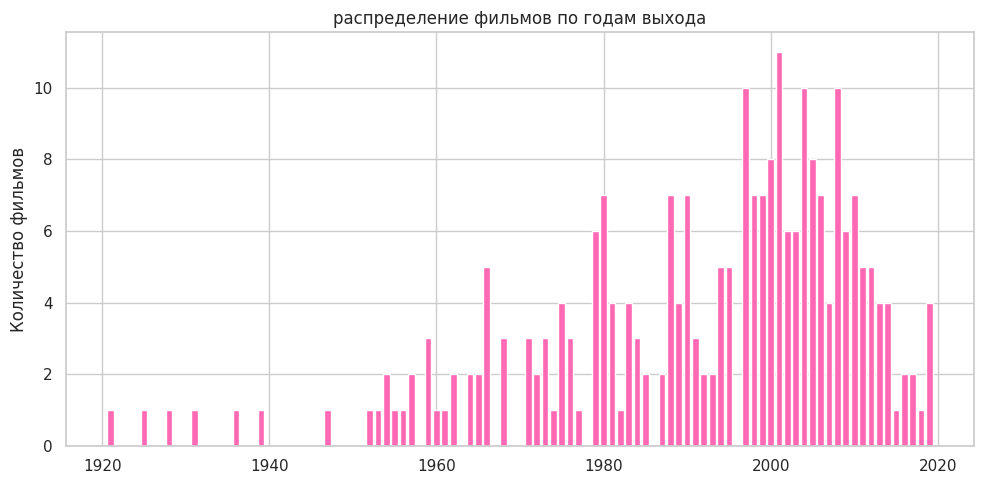

In [70]:
counts = df['year'].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values, color=['hotpink'])
plt.title('распределение фильмов по годам выхода')
plt.ylabel('Количество фильмов')
plt.tight_layout()
plt.show()

**Задание 7 (0.75 балла).**

Найдите и выведите самую короткую и самую длинную аннотацию фильма в корпусе. Здесь и далее длиной аннотации мы считаем число токенов, из которых она состоит.


In [79]:
df["amount"] = df["processed text"].str.split().str.len()
max = df[df['amount'] == df['amount'].max()]
max

,movie,year,country,rating_ball,overview,processed text,amount
70,Прислуга,2011,США,8.164,Американский Юг; на дворе 1960-е годы. Скитер ...,американский юг на двор 1960 е год скитер то...,163


In [80]:
min = df[df['amount'] == df['amount'].min()]
min

,movie,year,country,rating_ball,overview,processed text,amount
201,Цирк,1928,США,8.015,Грустная комедия о приключениях Чарли в состав...,грустный комедия о приключение чарли в сос...,9


**Задание 8 (0.75 балла).**

Выберите подходящий тип графика и визуализируйте распределение длин аннотаций в этом корпусе.

В отдельной текстовой ячейке ответьте на вопрос: насколько корректно это распределение отражает длины исходных аннотаций? Что в нашей предобработке могло исказить это распределение?

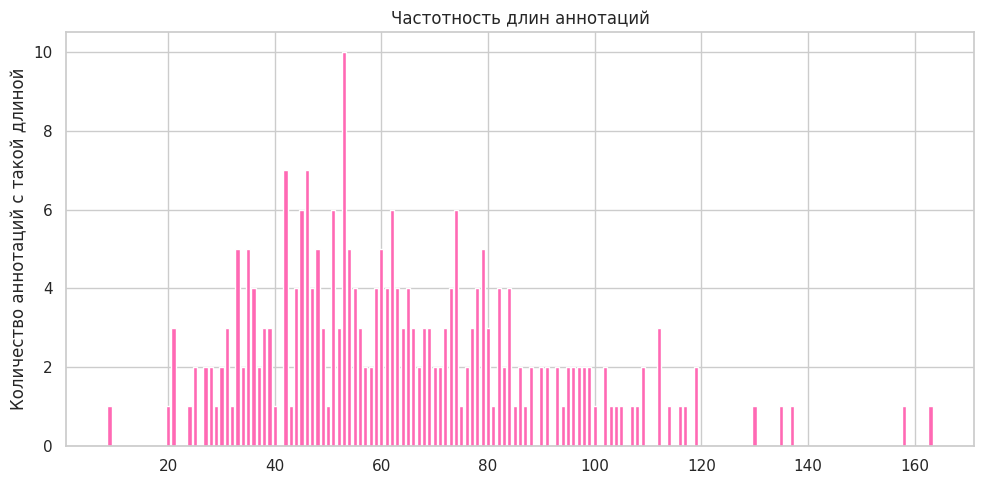

In [82]:
counts = df['amount'].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values, color=['hotpink'])
plt.title('Частотность длин аннотаций')
plt.ylabel('Количество аннотаций с такой длиной')
plt.tight_layout()
plt.show()



## Семантический анализ (4.5 балла)

В этом разделе вы будете работать с разными методами векторизации, искать именованные сущности и ключевые слова. Вам понадобятся не только материалы с пар, но и чтение документации. Все необходимые ссылки приведены в каждом конкретном задании.

**Задание 9 (0.75 балла).** В этом задании вам необходимо векторизовать тексты при помощи подходов «мешок слов» и «tf-idf».

В рамках этого курса мы работаем с реализациями этих алгоритмов из библиотеки sklearn. Документацию вы можете найти [здесь](https://scikit-learn.org/stable/). Семинар по этой теме был [здесь](https://github.com/hse-ling-python/hse-ling_26-27/blob/main/seminars/bow_tfidf_2026.ipynb).

Подумайте о том, какую именно версию текста необходимо векторизовать.

В отдельной ячейке ответьте на вопрос: какой размерности оказываются вектора текстов после использованных методов векторизации?

In [83]:
!pip install -q "numpy<3" "pandas<3" "scikit-learn<2" "matplotlib<4"

In [84]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.feature_extraction.text import (
    CountVectorizer, TfidfVectorizer, TfidfTransformer,
)
from sklearn.preprocessing import normalize

In [86]:
small_bow = CountVectorizer()
small_matrix = small_bow.fit_transform(d)
pd.DataFrame(small_matrix.toarray(), columns=small_bow.get_feature_names_out())
#Лиза сказала, что так норм
#если что, гриша там где-то назвал переменную янинг в честь колоночки в этой таблице

,000,1000,11,111,12,1200,1280,13,14,150,...,янинг,японец,япония,японский,яркий,ярко,ярлык,ярость,ярый,ящик
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
246,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
247,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
248,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


**Задание 10 (1.25 балла).** В этом задании вам необходимо получить вектор текста при помощи word2vec. Семинар по этой теме можно найти [здесь](https://github.com/hse-ling-python/hse-ling_26-27/blob/main/seminars/word2vec_bert_2026.ipynb). Документацию библиотеки gensim смотрите [здесь](https://radimrehurek.com/gensim/models/word2vec.html).

Обратите внимание, в каком именно формате модель word2vec получает слова – возможно вам придется написать дополнительную функцию предобработки для получения токенов в том формате, в котором это нужно для  модели word2vec. Для удобства можете создать отдельный столбец в датафрейме под названием «processed_w2v».

Для получения вектора предложения советуем также написать отдельную функцию и воспользоваться функционалом библиотеки [numpy](https://numpy.org/learn/). Не забывайте обрабатывать случаи, когда вектор слова внутри модели не был найден. В отдельной ячейке ниже поясните, как именно вы это делаете.

In [87]:
!pip install -q "gensim>=4.4,<5" "torch>=2.6,<3" "transformers>=4.57,<5" sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [88]:
import torch
from gensim.models import KeyedVectors
from transformers import AutoTokenizer, AutoModel

In [90]:
w2v_path = "models/ruscorpora_upos_skipgram_300_5_2018.vec.gz"
w2v_url = "https://rusvectores.org/static/models/rusvectores4/RNC/ruscorpora_upos_skipgram_300_5_2018.vec.gz"
!curl -L --fail --create-dirs -C - -o {w2v_path} {w2v_url}

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  190M  100  190M    0     0  11.9M      0  0:00:15  0:00:15 --:--:-- 14.1M


In [91]:
w2v = KeyedVectors.load_word2vec_format(w2v_path, binary=False)

In [94]:
def encode_w2v(items):
    result = []
    for keys in items:
        vectors = [w2v[key] for key in keys if key in w2v]
        vector = np.mean(vectors, axis=0) if vectors else np.zeros(w2v.vector_size)
        result.append(vector)
    return np.asarray(result)

X_w2v = encode_w2v(d)

**Задание 11 (0.75 балла).** В рамках каждого способа векторизации, написанного в предыдущих двух заданиях, при помощи косинусной близости найдите два самых **похожих** вектора (т.е. два самых похожих текста аннотации). Вычисление косинусной близости возьмите из библиотеки sklearn.

Выведите полученные пары текстов и метрику их сходства (если вы реализовали 3 метода векторизации, то пар должно быть тоже 3).

В отдельной ячейке ниже ответьте на вопросы: одинаковые ли тексты нашли разные методы векторизации или нет? Что это за тексты? Действительно ли они похожи?

In [109]:

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(df["overview"])

cosinus = cosine_similarity(tfidf_matrix, tfidf_matrix)
np.fill_diagonal(cosinus, 0)

idx1, idx2 = np.unravel_index(np.argmax(cosinus), cosinus.shape)
max_sim = cosinus[idx1, idx2]

print(f"Самые похожие фильмы (Косинусное сходство: {max_sim:.4f}):")
print(f"1. {df.iloc[idx1]['movie']} — '{df.iloc[idx1]['overview']}'")
print(f"2. {df.iloc[idx2]['movie']} — '{df.iloc[idx2]['overview']}'")

Самые похожие фильмы (Косинусное сходство: 0.2749):
1. Назад в будущее  — 'Подросток Марти с помощью машины времени; сооружённой его другом-профессором доком Брауном; попадает из 80-х в далекие 50-е. Там он встречается со своими будущими родителями; ещё подростками; и другом-профессором; совсем молодым.'
2. Назад в будущее 2  — 'Продолжение фантастической истории о приключениях американского подростка во времени. На этот раз с помощью модернизированной Доком машины времени Марти из 80-х попадает в будущее.Дети Марти в беде; и их надо выручать. Приходится повозиться со злодеем…'


In [111]:
count_vectorizer = CountVectorizer()
count_matrix = count_vectorizer.fit_transform(df["overview"])
sim_count = cosine_similarity(count_matrix)
print(sim_count)

[[1.         0.05786376 0.11514155 ... 0.07715167 0.06185896 0.        ]
 [0.05786376 1.         0.         ... 0.         0.         0.07426107]
 [0.11514155 0.         1.         ... 0.07106691 0.05698029 0.02111002]
 ...
 [0.07715167 0.         0.07106691 ... 1.         0.         0.        ]
 [0.06185896 0.         0.05698029 ... 0.         1.         0.02646281]
 [0.         0.07426107 0.02111002 ... 0.         0.02646281 1.        ]]


Для выполнения следующих двух заданий вам необходимо самостоятельно познакомиться с инструментами для выделения именованных сущностей (NER) и ключевых слов.

Для поиска именованных сущностей воспользуйтесь библиотекой [spaCy](https://spacy.io/).

Для поиска ключевых слов воспользуйтесь моделью [keyBERT](https://maartengr.github.io/KeyBERT/).

По приведенным ссылкам вы можете найти документацию и примеры кода.

**Задание 12 (0.5 балла).** Выделите из каждого текста аннотации именованные сущности и сделайте на их основе частотный словарь. Выведите самые популярные сущности и их частотность. Сохраните полученный словарь в формате `.json`.

В этом задании вы работаете с оригинальным текстом, а не предобработанным.

В отдельной ячейке ответьте на вопрос: соотносятся ли самые частотные именованные сущности с тематикой датасета? Какого рода сущности в основном самые частотные?

In [ ]:
# Ваш код здесь

**Задание 13 (1.25 балла).** В этом задании вам необходимо сравнить два подхода к поиску ключевых слов:
*   слова в документе с самой высокой метрикой `tf-idf`
*   использование модели `keyBERT`

Выберите случайный текст из датасета. Зафиксируйте свой выбор.

Сначала найдите в этом тексте ключевые слова при помощи `tf-idf`. Для этого выведите топ-5 слов с самой высокой метрикой `tf-idf`. Само значение метрики для каждого из слов тоже необходимо вывести.

Затем найдите в том же самом тексте ключевые слова при помощи модели `keyBERT`.

Сравните полученные два списка слов. В отдельной ячейке ответьте на вопросы: пересекаются ли эти списки слов? Какой подход, по вашему мнению, справился лучше?




In [ ]:
# Ваш код здесь